In [1]:
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "CSCO"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/AaryaAamishBhatt/Desktop/UC Berkeley/Python Course/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Aarya_Bhatt/data/data.db"


In [3]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scrapbook as sb

query = """
SELECT ts, ticker, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts BETWEEN ? AND ?
ORDER BY ts ASC
"""

with sqlite3.connect(db_path) as conn:
    df_stock = pd.read_sql_query(query, conn, params=(ticker.upper(), start_date, end_date), parse_dates=["ts"])

n_days = len(df_stock)
if n_days < 21:
    raise ValueError(f"Insufficient history for {ticker}: {n_days} trading days found, but >= 21 are required for 20-day volatility.")

actual_first = df_stock["ts"].min().strftime("%Y-%m-%d")
actual_last = df_stock["ts"].max().strftime("%Y-%m-%d")

print(f"{ticker} from {start_date} to {end_date}: {n_days} trading days")
print(f"Actual observation window in DB: {actual_first} to {actual_last}")
display(df_stock.head(3))
display(df_stock.tail(3))

CSCO from 2024-06-01 to 2024-11-30: 97 trading days
Actual observation window in DB: 2024-06-03 to 2024-10-18


,ts,ticker,open,high,low,close,adj_close,volume
0,2024-06-03,CSCO,46.72,46.77,46.28,46.65,45.90,23295000
1,2024-06-04,CSCO,46.65,47.60,46.51,47.42,46.66,23330316
2,2024-06-05,CSCO,47.52,47.63,45.64,46.02,45.28,28746400


,ts,ticker,open,high,low,close,adj_close,volume
94,2024-10-16,CSCO,55.00,56.41,54.83,56.38,56.38,32382300
95,2024-10-17,CSCO,56.38,56.58,55.85,56.40,56.40,18383351
96,2024-10-18,CSCO,56.41,56.87,56.21,56.74,56.74,16142036


#2.3

In [4]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns."""
    return np.log(prices / prices.shift(1))

def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility using sample std dev."""
    return returns.rolling(window=window, min_periods=window).std(ddof=1) * np.sqrt(252)

def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    cum_max = prices.cummax()
    return (prices - cum_max) / cum_max

def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio using course approximation."""
    clean_ret = returns.dropna()
    if len(clean_ret) < 2:
        return np.nan
    std_ret = clean_ret.std(ddof=1)
    if pd.isna(std_ret) or std_ret == 0:
        return np.nan
    return float((clean_ret.mean() * 252 - risk_free_rate) / (std_ret * np.sqrt(252)))

df_stock = df_stock.set_index("ts")
prices = df_stock["adj_close"]
log_rets = calculate_returns(prices)
roll_vol = calculate_volatility(log_rets, window=20)
dd_series = calculate_max_drawdown(prices)
sharpe = calculate_sharpe_ratio(log_rets, risk_free_rate=0.02)

#2.4

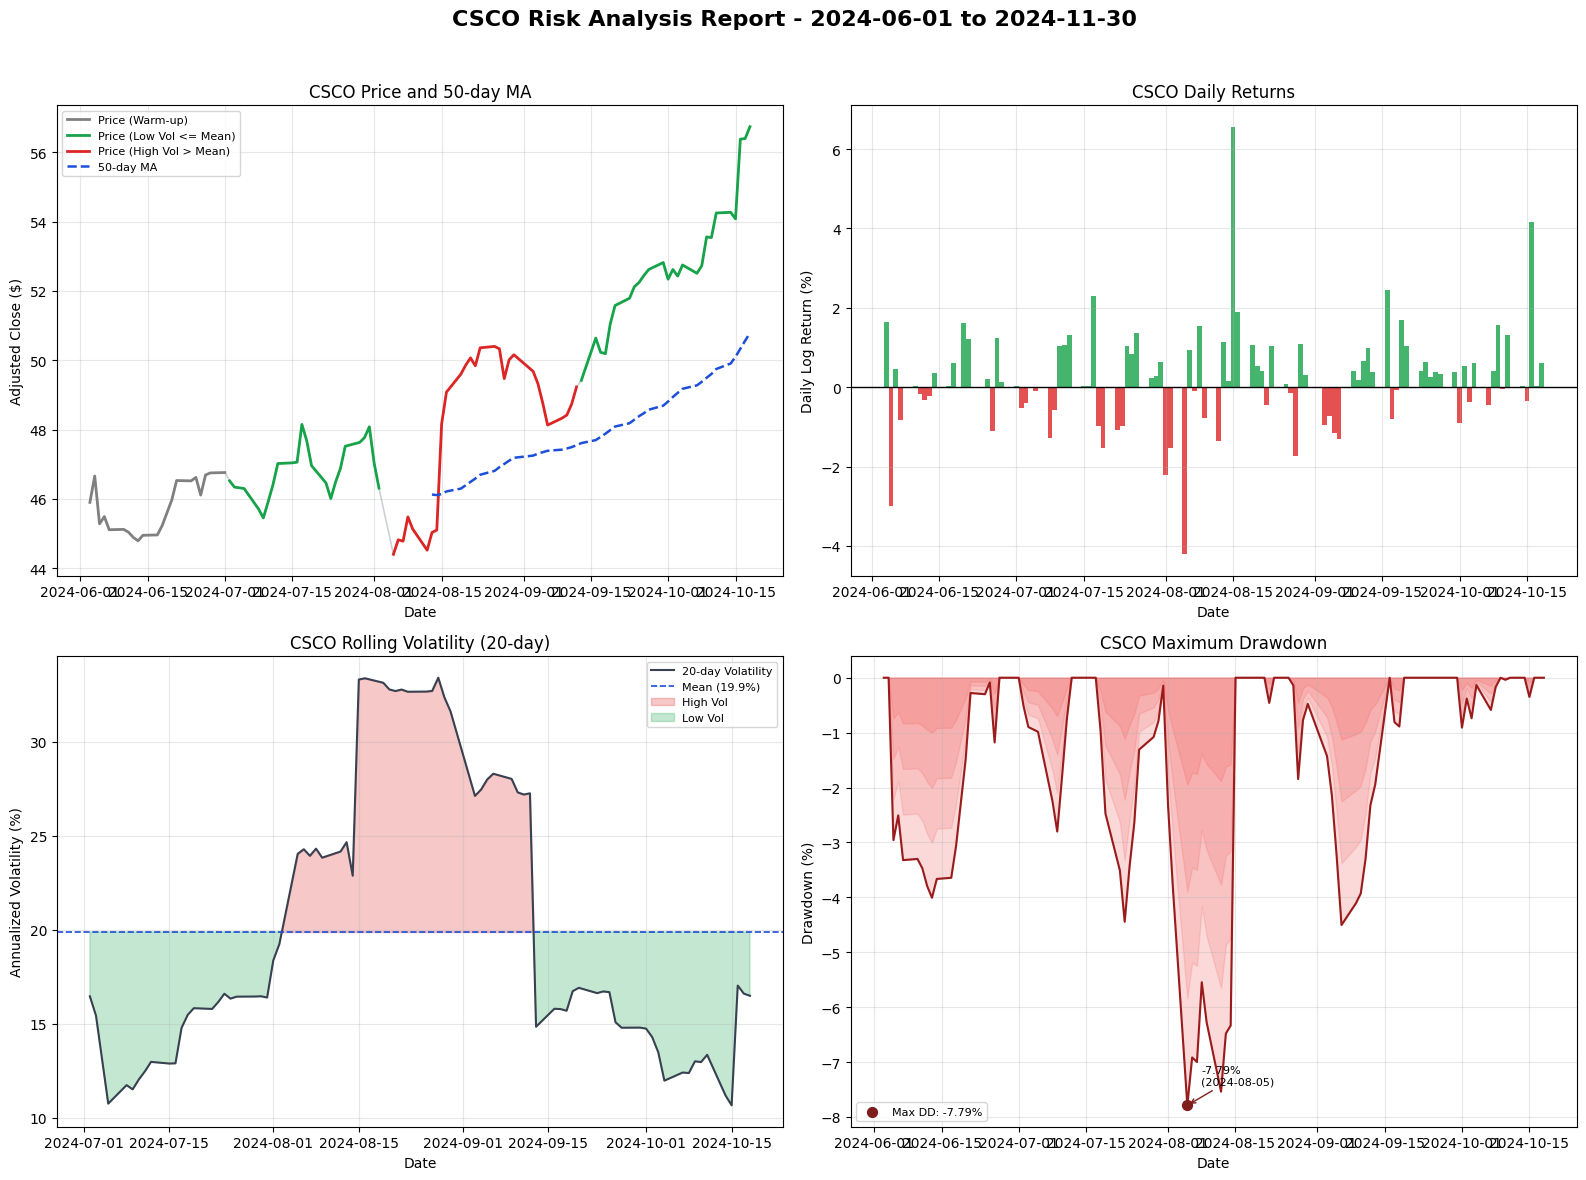

In [5]:
ma_50 = prices.rolling(window=50, min_periods=50).mean()
mean_roll_vol = roll_vol.mean()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=16, fontweight="bold")

# --- Top Left: Price and 50-day MA colored by Volatility Regime ---
ax1 = axes[0, 0]
# Plot a faint base line so transitions connect smoothly, then overlay colored regimes
ax1.plot(prices.index, prices, color="#9ca3af", lw=1.2, alpha=0.5)

warmup_mask = roll_vol.isna()
low_vol_mask = (roll_vol <= mean_roll_vol)
high_vol_mask = (roll_vol > mean_roll_vol)

ax1.plot(prices.index, prices.where(warmup_mask), color="gray", lw=2, label="Price (Warm-up)")
ax1.plot(prices.index, prices.where(low_vol_mask), color="#16a34a", lw=2, label="Price (Low Vol <= Mean)")
ax1.plot(prices.index, prices.where(high_vol_mask), color="#dc2626", lw=2, label="Price (High Vol > Mean)")

if ma_50.notna().any():
    ax1.plot(ma_50.index, ma_50, color="#1d4ed8", ls="--", lw=1.8, label="50-day MA")
else:
    ax1.text(0.05, 0.9, "50-day MA unavailable (<50 obs)", transform=ax1.transAxes, fontsize=9)

ax1.set_title(f"{ticker} Price and 50-day MA")
ax1.set_xlabel("Date")
ax1.set_ylabel("Adjusted Close ($)")
ax1.legend(loc="best", fontsize=8)
ax1.grid(True, alpha=0.3)

# --- Top Right: Daily Returns ---
ax2 = axes[0, 1]
ret_clean = log_rets.dropna()
bar_colors = np.where(ret_clean >= 0, "#16a34a", "#dc2626")
ax2.bar(ret_clean.index, ret_clean * 100, color=bar_colors, width=1.0, alpha=0.8)
ax2.axhline(0, color="black", lw=1)
ax2.set_title(f"{ticker} Daily Returns")
ax2.set_xlabel("Date")
ax2.set_ylabel("Daily Log Return (%)")
ax2.grid(True, alpha=0.3)

# --- Bottom Left: Rolling Volatility (20-day) ---
ax3 = axes[1, 0]
ax3.plot(roll_vol.index, roll_vol * 100, color="#374151", lw=1.5, label="20-day Volatility")
if pd.notna(mean_roll_vol):
    ax3.axhline(mean_roll_vol * 100, color="#1d4ed8", ls="--", lw=1.2, label=f"Mean ({mean_roll_vol*100:.1f}%)")
    ax3.fill_between(roll_vol.index, roll_vol * 100, mean_roll_vol * 100,
                     where=(roll_vol > mean_roll_vol), color="#dc2626", alpha=0.25, interpolate=True, label="High Vol")
    ax3.fill_between(roll_vol.index, roll_vol * 100, mean_roll_vol * 100,
                     where=(roll_vol <= mean_roll_vol), color="#16a34a", alpha=0.25, interpolate=True, label="Low Vol")
ax3.set_title(f"{ticker} Rolling Volatility (20-day)")
ax3.set_xlabel("Date")
ax3.set_ylabel("Annualized Volatility (%)")
ax3.legend(loc="best", fontsize=8)
ax3.grid(True, alpha=0.3)

# --- Bottom Right: Maximum Drawdown ---
ax4 = axes[1, 1]
dd_pct = dd_series * 100
ax4.plot(dd_pct.index, dd_pct, color="#991b1b", lw=1.5)
# Layered fills for pink/red gradient
for factor, alpha in [(0.25, 0.15), (0.5, 0.15), (0.75, 0.15), (1.0, 0.2)]:
    ax4.fill_between(dd_pct.index, dd_pct * factor, 0, color="#ef4444", alpha=alpha)

min_dd_date = dd_series.idxmin()
min_dd_val = dd_series.loc[min_dd_date]
ax4.scatter([min_dd_date], [min_dd_val * 100], color="#7f1d1d", zorder=5, s=50, label=f"Max DD: {min_dd_val*100:.2f}%")
ax4.annotate(f"{min_dd_val*100:.2f}%\n({min_dd_date.strftime('%Y-%m-%d')})",
             xy=(min_dd_date, min_dd_val * 100), xytext=(10, 15),
             textcoords="offset points", arrowprops=dict(arrowstyle="->", color="#7f1d1d"), fontsize=8)
ax4.set_title(f"{ticker} Maximum Drawdown")
ax4.set_xlabel("Date")
ax4.set_ylabel("Drawdown (%)")
ax4.legend(loc="lower left", fontsize=8)
ax4.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [6]:
import scrapbook as sb
import pandas as pd
import numpy as np

# Safely compute portfolio metrics for Scrapbook collection
try:
    tkr_str = str(globals().get("ticker", "UNKNOWN"))
    mean_ret = mean_ret = float(log_rets.dropna().mean())
    mean_vol = float(roll_vol.mean()) if 'roll_vol' in globals() and roll_vol is not None else 0.0
    m_dd = float(dd_series.min()) if 'dd_series' in globals() and dd_series is not None else 0.0
    s_ratio = float(sharpe) if 'sharpe' in globals() and sharpe is not None and pd.notna(sharpe) else None
    t_ret = float(prices.iloc[-1] / prices.iloc[0] - 1.0) if 'prices' in globals() and len(prices) > 0 else 0.0
    a_first = df_stock.index.min().strftime("%Y-%m-%d") if 'df_stock' in globals() and not df_stock.empty else ""
    a_last = df_stock.index.max().strftime("%Y-%m-%d") if 'df_stock' in globals() and not df_stock.empty else ""
    d_count = int(len(df_stock)) if 'df_stock' in globals() and df_stock is not None else 0
except Exception as e:
    print(f"Warning during scrapbook collection: {e}")
    tkr_str = "UNKNOWN"
    mean_ret = mean_vol = m_dd = t_ret = 0.0
    s_ratio = None
    a_first = a_last = ""
    d_count = 0

# Glue the metrics so Part 3 can read them via scrapbook
sb.glue("portfolio_metrics", {
    "ticker": tkr_str.upper(),
    "avg_daily_return": mean_ret,
    "avg_volatility": mean_vol,
    "max_drawdown": m_dd,
    "sharpe_ratio": s_ratio,
    "total_return": t_ret,
    "actual_start": a_first,
    "actual_end": a_last,
    "trading_days": d_count
})

print(f"Successfully glued portfolio_metrics for {tkr_str}")

Successfully glued portfolio_metrics for CSCO
